In [15]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
# import altair as alt
#import pandas as pd
import numpy as np

import mygene
import pyperclip

import glob
import os
import sys
import math

mpl.rcParams.update({
    "pdf.fonttype": 42,           # TrueType = editable text
    "font.family": "Arial", # or Arial, Helvetica
    "text.usetex": False          # Absolutely must be False
})

In [17]:
CD55_ID = "ENSG00000196352"
# actual locus chr1:207,321,678-207,360,966
#with promoter chr1:207,320,678-207,360,966
INPUT_DIR = "/Users/p.coli/Desktop/CRISPRtune/RPE_CUTRUN/diffbind/diffbind_broad/DiffBind_broad/edgeR/"
OUTPUT_DIR = "/Users/p.coli/Desktop/CRISPRtune/RPE_CUTRUN/Diff_bind_volcanoplots/"

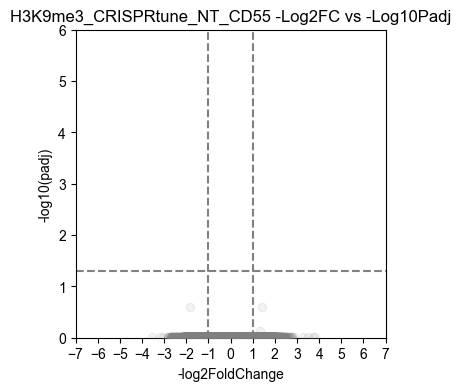

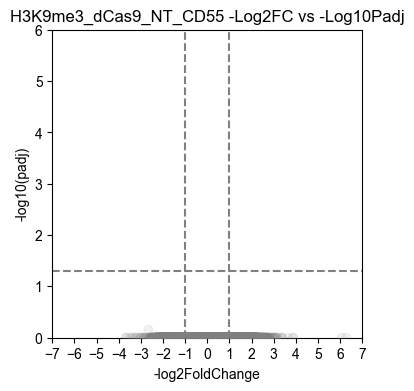

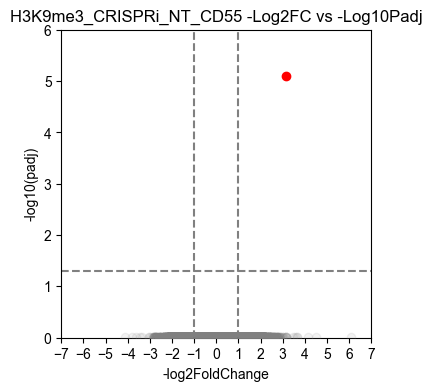

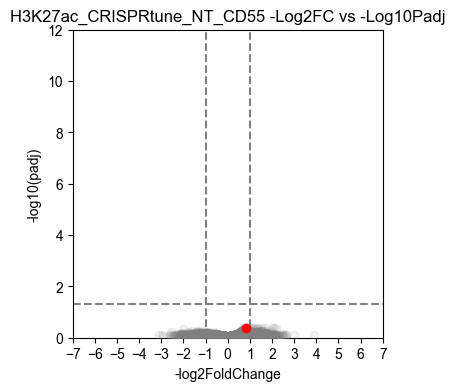

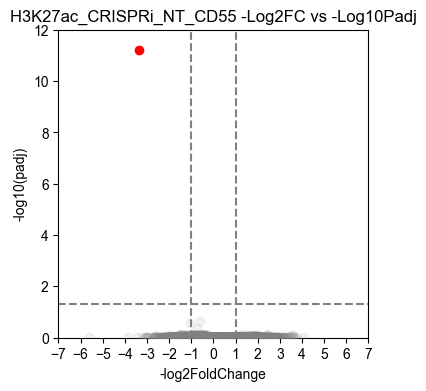

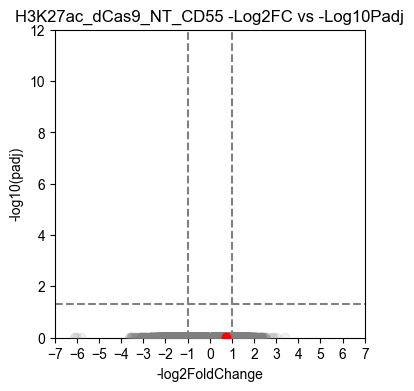

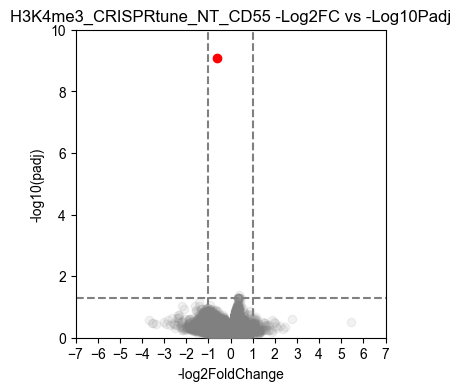

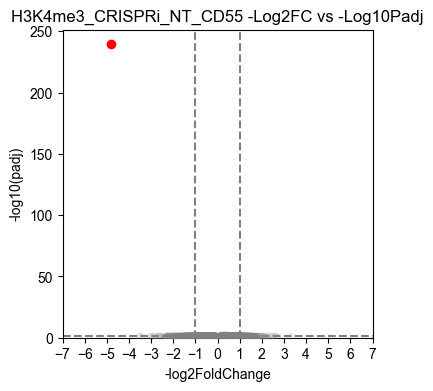

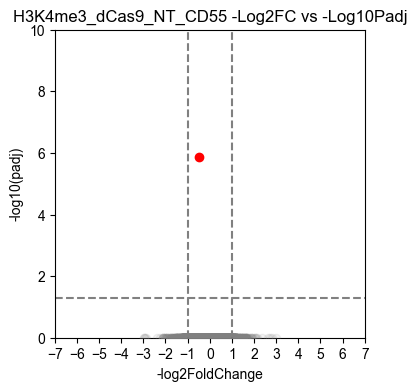

In [45]:
# Makes plots
DESeq_dict = {}
order = ["H3K9me3","H3K27ac","H3K4me3"]
for i in order:
    for file in glob.glob(f"{INPUT_DIR}edgeR_{i}*_NT_CD55.csv"):
        plot_name = (os.path.basename(file)).replace("edgeR_", "").replace(".csv", "")
        df = pl.read_csv(file, null_values=["NA"])
        df = df.with_columns(
            ((pl.col("Fold") * -1).alias("neg_log2_Fold")),
            ((pl.col("FDR").log10() * -1).alias("neg_log10_fdr"))
        )
        if i != "H3K9me3":
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+2000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )
        else:
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+3000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )
              
        xticks = np.arange(-7, 8, 1)
        
        
        if i == "H3K9me3":
            yticks = np.arange(0, 7, 1)
            
            
        elif i == "H3K27ac":
            yticks = np.arange(0, 14, 2)
            
        elif i == "H3K4me3":
            if "CRISPRi" in plot_name:
                yticks = np.arange(0, 251, 50)
            else:
                yticks = np.arange(0, 12, 2)

        fig, ax = plt.subplots(1, 1, figsize=(4, 4))

        for (c,), g in df.group_by("color"):
            if c == "red":
                alpha = 1
                zorder = 10
            else:
                alpha = 0.1
                zorder = 5
            ax.scatter(g["neg_log2_Fold"], g["neg_log10_fdr"], color=c, alpha=alpha, zorder=zorder,rasterized=True,)

        ax.set_xticks(xticks)
        ax.set_yticks(yticks)
        ax.set_ylim(bottom=0)


        ax.set_xlabel("-log2FoldChange")
        ax.set_ylabel("-log10(padj)")

        plt.axvline(x=-1, color='gray', linestyle='--', label='Cutoff')
        plt.axvline(x=1, color='gray', linestyle='--', label='Cutoff')
        plt.axhline(y=1.3010299956639813, color='gray', linestyle='--', label='Cutoff')
        ax.set_title(f"{plot_name} -Log2FC vs -Log10Padj", fontsize=12, color="black")
        mpl.rcParams['svg.fonttype'] = 'none'
        
        fig.savefig(OUTPUT_DIR + "png/" +f"{plot_name}.png", format="png", dpi = 500)
        fig.savefig(OUTPUT_DIR + "svg/" +f"{plot_name}.svg", format="svg", dpi = 300)


In [35]:
# Makes plots
DESeq_dict = {}
order = ["H3K9me3"]#,"H3K27ac","H3K4me3"]
for i in order:
    for file in glob.glob(f"{INPUT_DIR}edgeR_{i}*_NT_CD55.csv"):
        plot_name = (os.path.basename(file)).replace("edgeR_", "").replace(".csv", "")
        df = pl.read_csv(file, null_values=["NA"])
        df = df.with_columns(
            ((pl.col("Fold") * -1).alias("neg_log2_Fold")),
            ((pl.col("FDR").log10() * -1).alias("neg_log10_fdr"))
        )
        if i != "H3K9me3":
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+2000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )
        else:
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+3000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )
              
    print(df.filter(pl.col("neg_log10_fdr") == 0))

shape: (0, 15)
┌─────┬──────────┬───────┬─────┬───┬─────┬───────────────┬───────────────┬───────┐
│     ┆ seqnames ┆ start ┆ end ┆ … ┆ FDR ┆ neg_log2_Fold ┆ neg_log10_fdr ┆ color │
│ --- ┆ ---      ┆ ---   ┆ --- ┆   ┆ --- ┆ ---           ┆ ---           ┆ ---   │
│ i64 ┆ str      ┆ i64   ┆ i64 ┆   ┆ f64 ┆ f64           ┆ f64           ┆ str   │
╞═════╪══════════╪═══════╪═════╪═══╪═════╪═══════════════╪═══════════════╪═══════╡
└─────┴──────────┴───────┴─────┴───┴─────┴───────────────┴───────────────┴───────┘


In [25]:
# find CD55 Stats
DESeq_dict = {}
order = ["H3K27ac"]#["H3K9me3","H3K27ac","H3K4me3"]
for i in order:
    for file in glob.glob(f"{INPUT_DIR}edgeR_{i}*_NT_CD55.csv"):
        plot_name = (os.path.basename(file)).replace("edgeR_", "").replace(".csv", "")
        df = pl.read_csv(file, null_values=["NA"])
        df = df.with_columns(
            ((pl.col("Fold") * -1).alias("neg_log2_Fold")),
            ((pl.col("FDR").log10() * -1).alias("neg_log10_fdr"))
        )
        if i != "H3K9me3":
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+2000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )
        else:
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+3000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )#.filter(pl.col("CD55") == "red")
        print(plot_name,df.filter(pl.col("color") == "red"))#.select(["seqnames","start","end","Fold", "FDR", "color"]))

H3K27ac_CRISPRtune_NT_CD55 shape: (1, 15)
┌──────┬──────────┬───────────┬───────────┬───┬──────────┬───────────────┬───────────────┬───────┐
│      ┆ seqnames ┆ start     ┆ end       ┆ … ┆ FDR      ┆ neg_log2_Fold ┆ neg_log10_fdr ┆ color │
│ ---  ┆ ---      ┆ ---       ┆ ---       ┆   ┆ ---      ┆ ---           ┆ ---           ┆ ---   │
│ i64  ┆ str      ┆ i64       ┆ i64       ┆   ┆ f64      ┆ f64           ┆ f64           ┆ str   │
╞══════╪══════════╪═══════════╪═══════════╪═══╪══════════╪═══════════════╪═══════════════╪═══════╡
│ 7665 ┆ chr1     ┆ 207321858 ┆ 207322258 ┆ … ┆ 0.425088 ┆ 0.842963      ┆ 0.371521      ┆ red   │
└──────┴──────────┴───────────┴───────────┴───┴──────────┴───────────────┴───────────────┴───────┘
H3K27ac_CRISPRi_NT_CD55 shape: (1, 15)
┌──────┬──────────┬───────────┬───────────┬───┬────────────┬───────────────┬───────────────┬───────┐
│      ┆ seqnames ┆ start     ┆ end       ┆ … ┆ FDR        ┆ neg_log2_Fold ┆ neg_log10_fdr ┆ color │
│ ---  ┆ ---      ┆ --- 

In [77]:
# Off target
off_target_list =[]
DESeq_dict = {}
order = ["H3K9me3","H3K27ac","H3K4me3"]
for i in order:
    for file in glob.glob(f"{INPUT_DIR}edgeR_{i}*_NT_CD55.csv"):
        plot_name = (os.path.basename(file)).replace("edgeR_", "").replace(".csv", "")
        df = pl.read_csv(file, null_values=["NA"])
        df = df.with_columns(
            ((pl.col("Fold") * -1).alias("neg_log2_Fold")),
            ((pl.col("FDR").log10() * -1).alias("neg_log10_fdr"))
        )
        if i != "H3K9me3":
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+2000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )
        else:
            df = df.with_columns(
                pl.when(
                    (pl.col("seqnames") == "chr1") & 
                    # (pl.col("start") > 207_321_000) &
                    # (pl.col("start") < 207_340_000)
                    (pl.col("start") > 207_321_678-2000) &
                    (pl.col("end") < 207_321_678+3000)
                ).then(pl.lit("red")).otherwise(pl.lit("grey")).alias("color")
            )
            
        filtered_df = df.filter(
            (pl.col("neg_log2_Fold") < -1) &
            (pl.col("neg_log10_fdr") > 1.3010299956639813)).with_columns(pl.lit(plot_name).alias("editor"))
        new_col_names = 
        print(filtered_df.columns)


['', 'seqnames', 'start', 'end', 'width', 'strand', 'Conc', 'Conc_CRISPRtune_NT', 'Conc_CRISPRtune_CD55', 'Fold', 'p.value', 'FDR', 'neg_log2_Fold', 'neg_log10_fdr', 'color', 'editor']
['', 'seqnames', 'start', 'end', 'width', 'strand', 'Conc', 'Conc_dCas9_NT', 'Conc_dCas9_CD55', 'Fold', 'p.value', 'FDR', 'neg_log2_Fold', 'neg_log10_fdr', 'color', 'editor']
['', 'seqnames', 'start', 'end', 'width', 'strand', 'Conc', 'Conc_CRISPRi_NT', 'Conc_CRISPRi_CD55', 'Fold', 'p.value', 'FDR', 'neg_log2_Fold', 'neg_log10_fdr', 'color', 'editor']
['', 'seqnames', 'start', 'end', 'width', 'strand', 'Conc', 'Conc_CRISPRtune_NT', 'Conc_CRISPRtune_CD55', 'Fold', 'p.value', 'FDR', 'neg_log2_Fold', 'neg_log10_fdr', 'color', 'editor']
['', 'seqnames', 'start', 'end', 'width', 'strand', 'Conc', 'Conc_CRISPRi_NT', 'Conc_CRISPRi_CD55', 'Fold', 'p.value', 'FDR', 'neg_log2_Fold', 'neg_log10_fdr', 'color', 'editor']
['', 'seqnames', 'start', 'end', 'width', 'strand', 'Conc', 'Conc_dCas9_NT', 'Conc_dCas9_CD55', '

In [65]:
off_target_list[4]

,seqnames,start,end,width,strand,Conc,Conc_CRISPRi_NT,Conc_CRISPRi_CD55,Fold,p.value,FDR,neg_log2_Fold,neg_log10_fdr,color,editor
i64,str,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,str,str
8169,"""chr1""",207321950,207322350,401,"""*""",4.615827,5.476905,2.1705,3.372029,5.7004e-17,5.9813e-12,-3.372029,11.223205,"""red""","""H3K27ac_CRISPRi_NT_CD55"""


In [6]:
print(mpl.__version__)

3.10.3


AttributeError: module 'matplotlib' has no attribute 'citation'